In [ ]:
#Meshal Mahnoor

Access my Images here: https://drive.google.com/drive/folders/1XKLlhng-zBxMi0qmtkxemcGk121EYRgk?usp=sharing

In [ ]:
#imports
import cv2
import numpy as np
import matplotlib.pyplot as plt

Lab Task 1:
Load and display the left and right stereo images using OpenCV. Verify that both images have
the same dimensions and identify the corresponding horizontal epipolar line for a selected image
row.

In [ ]:
# Load the grayscale stereo images
img_left = cv2.imread('Il.jpg', 0)
img_right = cv2.imread('Ir.jpg', 0)

In [ ]:
#pre processing, converting the image to same dimensions:
height, width = img_left.shape[:2]

# Resize image B to match image A's dimensions (Width, Height)
image_right_resized = cv2.resize(img_right, (width, height))

Left image shape: (628, 628)
Right image shape: (628, 628)


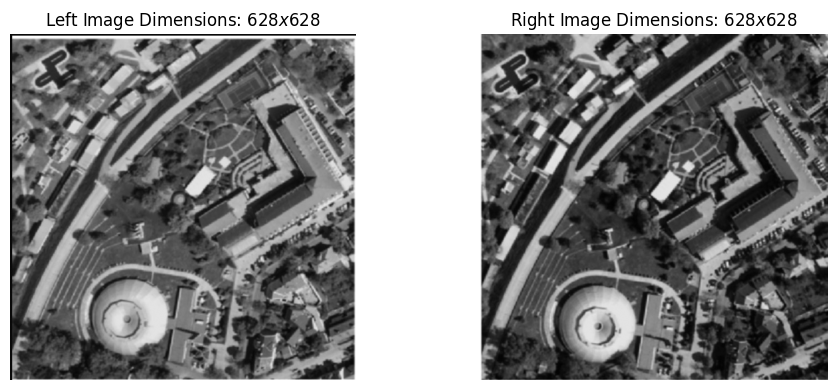

In [ ]:
# Check if images loaded successfully
if img_left is None or image_right_resized is None:
 print("Error: Could not load image(s). Check file paths and formats.")
 raise FileNotFoundError("Stereo image(s) could not be loaded.")
# Check image dimensions
print("Left image shape:", img_left.shape)
print("Right image shape:", image_right_resized.shape)
height_left, width_left = img_left.shape
height, width = image_right_resized.shape
# Display the stereo images
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img_left, cmap='gray')
plt.title(f"Left Image Dimensions: ${height_left}x ${width_left}")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(img_right, cmap='gray')
plt.title(f'Right Image Dimensions: ${height} x${width}')
plt.axis('off')
plt.tight_layout()
plt.show()

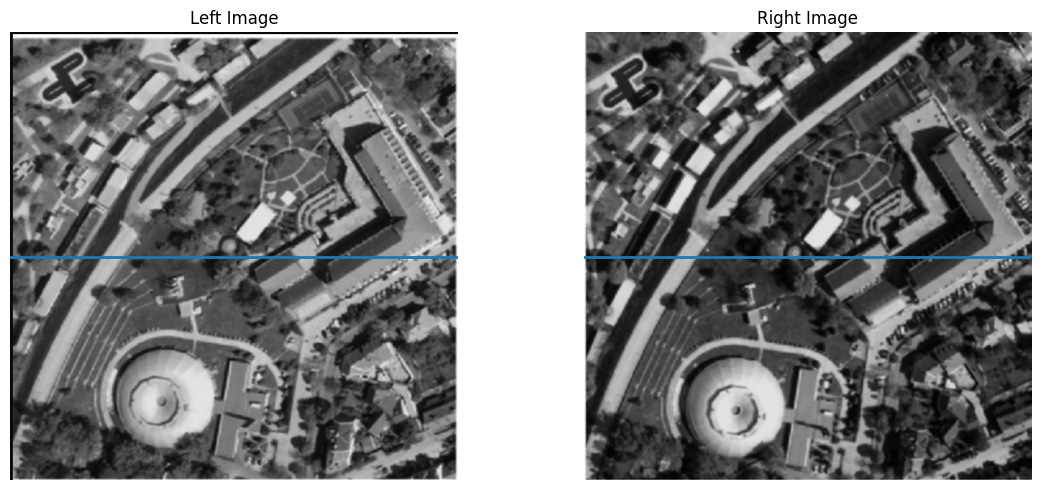

In [ ]:
# Select a row in the images
row = img_left.shape[0] // 2
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_left, cmap='gray')
plt.axhline(row, linewidth=2)
plt.title('Left Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(image_right_resized, cmap='gray')
plt.axhline(row, linewidth=2)
plt.title('Right Image')
plt.axis('off')
plt.tight_layout()
plt.show()

**Lab Task 2:**
Implement SSD-based stereo matching and generate disparity maps using 7×7 and 31×31
matching windows. Display both disparity maps and compare the effect of the two window sizes.

**Observations:**
Formula used for this:
SSD = Σ (IL − IR)2


The 7x7 window shows the image a bit more detail where you can atleast somewhat makeout the details of the image. In the 31x31 window we can see a more "abstract" version of the image. We can make out the disparity of the data from the graph and color scheme, but not so much the fine details of the image.

In [ ]:
#indentations fixeed:
def compute_ssd_disparity(left_img, right_img, window_size, max_disparity=30):
    # Get image dimensions
    h, w = left_img.shape

    # Half of the window size
    half = window_size // 2

    # Create an empty disparity map
    disparity_map = np.zeros((h, w), dtype=np.float32)

    # Convert images to float for subtraction
    left_img = left_img.astype(np.float32)
    right_img = right_img.astype(np.float32)

    # Loop through valid image pixels
    for y in range(half, h - half):
        for x in range(half + max_disparity, w - half):
            # Extract the left image patch
            left_patch = left_img[
                y-half : y+half+1,
                x-half : x+half+1
            ]

            min_ssd = float('inf')
            best_disparity = 0

            # Search over possible disparities
            for disparity in range(max_disparity):
                x_right = x - disparity

                # Check image boundary
                if x_right - half < 0:
                    break

                # Extract the corresponding right image patch
                right_patch = right_img[
                    y-half : y+half+1,
                    x_right-half : x_right+half+1
                ]

                # Calculate SSD
                ssd = np.sum((left_patch - right_patch) ** 2)

                # Find the best match
                if ssd < min_ssd:
                    min_ssd = ssd
                    best_disparity = disparity

            # Store best disparity
            disparity_map[y, x] = best_disparity

    return disparity_map

# Compute Disparity
disp_7 = compute_ssd_disparity(
    img_left,
    image_right_resized,
    window_size=7,
    max_disparity=30
)

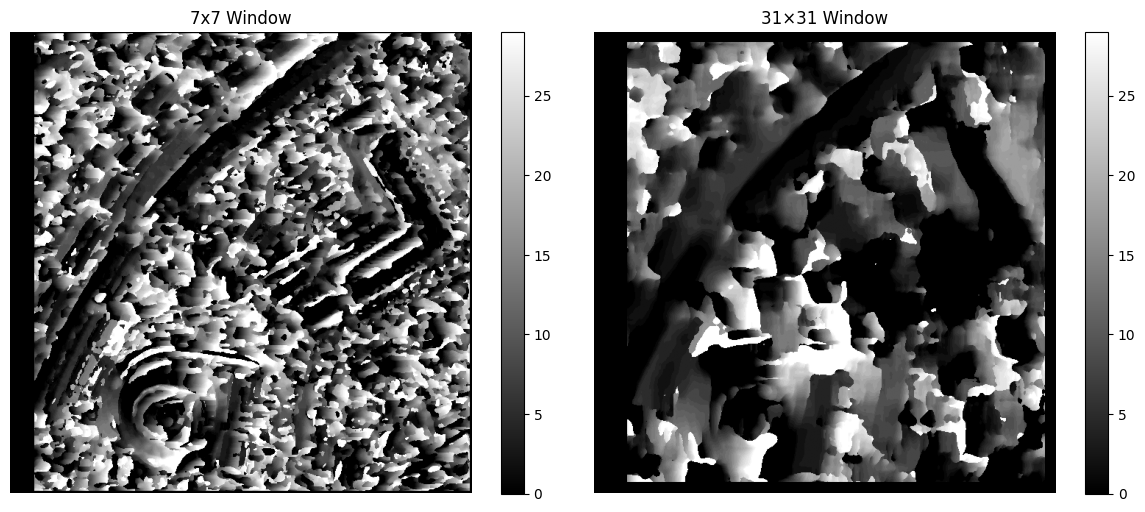

In [ ]:
#plotting both alongside eachother:
disp_31 = compute_ssd_disparity(
img_left,
image_right_resized,
window_size=31,
max_disparity=30
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(disp_7, cmap='gray')
plt.colorbar()
plt.title('7x7 Window')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(disp_31, cmap='gray')
plt.colorbar()
plt.title('31×31 Window')
plt.axis('off')
plt.tight_layout()
plt.show()

**Lab Task 3:**
Use the disparity map obtained with the 7×7 window to calculate the depth map using:


*Z=fB/d.*



Use (B = 0.54) m and (f = 721.5) pixels. Display the resulting depth map.

The following plot shows the depth map for the 7x7 disparity map.

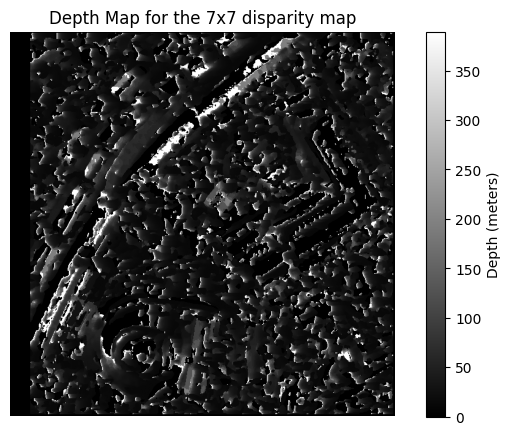

In [ ]:
#depth map:
B = 0.54 # Baseline in meters
f = 721.5 # Focal length in pixels
def compute_depth(disparity_map, baseline, focal_length):
 depth_map = np.zeros_like(
 disparity_map,
 dtype=np.float32
 )
# Only calculate depth where disparity is positive
 valid = disparity_map > 0
 depth_map[valid] = (
 baseline * focal_length
 ) / disparity_map[valid]
 return depth_map

#computing depth map
depth_map = compute_depth(
disp_7, #using the 7x7 disparity map
B,
f
)
#plotting
plt.figure(figsize=(8, 5))

plt.imshow(depth_map, cmap='gray')
plt.colorbar(label='Depth (meters)')
plt.title('Depth Map for the 7x7 disparity map')
plt.axis('off')
plt.show()

**Lab Task 4:**
Investigate how changing the baseline, focal length, and disparity affects the calculated depth.
Use different values for each parameter and report the resulting depth values. Briefly explain
your observations.

In [ ]:
B = 0.54
f = 721.5
disparities = [5, 10, 20, 30]

for d in disparities:
 depth = (B * f) / d
 print(
 f"Disparity = {d:2d} pixels "
 f"-> Depth = {depth:.2f} meters"
 )

f = 721.5
d = 20
baselines = [0.30, 0.54, 1.00]
for B in baselines:
 depth = (B * f) / d
 print(
 f"Baseline = {B:.2f} m "
 f"-> Depth = {depth:.2f} m"
 )

B = 0.54
d = 20
focal_lengths = [500, 721.5, 1000]
for f in focal_lengths:
 depth = (B * f) / d
 print(
 f"Focal Length = {f:.1f} pixels "
 f"-> Depth = {depth:.2f} m"
 )

Disparity =  5 pixels -> Depth = 77.92 meters
Disparity = 10 pixels -> Depth = 38.96 meters
Disparity = 20 pixels -> Depth = 19.48 meters
Disparity = 30 pixels -> Depth = 12.99 meters
Baseline = 0.30 m -> Depth = 10.82 m
Baseline = 0.54 m -> Depth = 19.48 m
Baseline = 1.00 m -> Depth = 36.08 m
Focal Length = 500.0 pixels -> Depth = 13.50 m
Focal Length = 721.5 pixels -> Depth = 19.48 m
Focal Length = 1000.0 pixels -> Depth = 27.00 m


***Observations:***
As disparity increases, the depth is decreasing. This is also evident from the mathematical formula where d^ Z↓

## ***Z=fB/d.   --- i***  
Z = 1/d

The Baseline increasing also increases the depth, as evident by formula **i** and above values.

Increasing focal length also increases the depth for the disparity, as evident by formula **i** and values above.

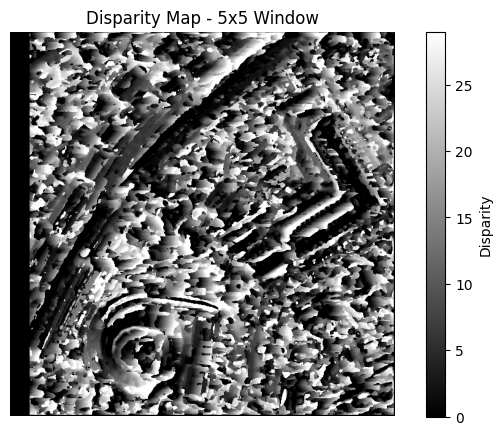

In [ ]:
#Visualised for some Value:
disp_5 = compute_ssd_disparity(
img_left,
image_right_resized,
window_size=5,
max_disparity=30
)
plt.figure(figsize=(8, 5))
plt.imshow(disp_5, cmap='gray')
plt.colorbar(label='Disparity')
plt.title('Disparity Map - 5x5 Window')
plt.axis('off')
plt.show()

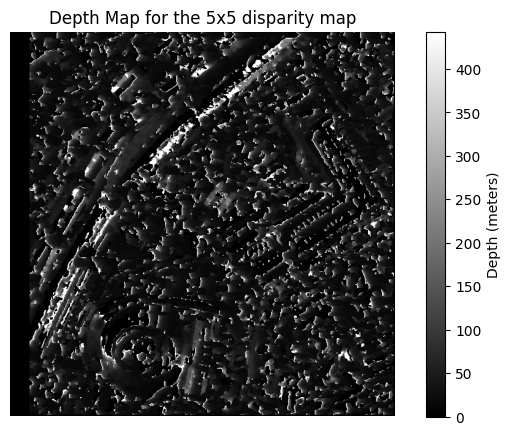

Baseline = 0.59 m -> Depth = 22.14 m
Focal Length = 750.5 pixels -> Depth = 22.14 m


In [ ]:
#depth map for a 5x5 disparity map:
B = 0.59 # Baseline in meters
f = 750.5 # Focal length in pixels
def compute_depth(disparity_map, baseline, focal_length):
 depth_map = np.zeros_like(
 disparity_map,
 dtype=np.float32
 )
# Only calculate depth where disparity is positive
 valid = disparity_map > 0
 depth_map[valid] = (
 baseline * focal_length
 ) / disparity_map[valid]
 return depth_map

#computing depth map
depth_map = compute_depth(
disp_5, #using the 5x5 disparity map
B,
f
)
#plotting
plt.figure(figsize=(8, 5))

plt.imshow(depth_map, cmap='gray')
plt.colorbar(label='Depth (meters)')
plt.title('Depth Map for the 5x5 disparity map')
plt.axis('off')
plt.show()

depth = (B * f) / d
print(
 f"Baseline = {B:.2f} m "
 f"-> Depth = {depth:.2f} m"
 )
depth = (B * f) / d
print(
 f"Focal Length = {f:.1f} pixels "
 f"-> Depth = {depth:.2f} m"
 )

The Baseline increasing also increases the depth.

Increasing focal length also increases the depth for the disparity.